# Monte Carlo option pricing

Pricing European options with the Black-Scholes formula and then by Monte Carlo simulation of the stock price, to see how the simulation converges and how to make it converge faster. Then using the same simulation for options that don't have a simple formula (Asian and barrier options), and estimating the Greeks.

In [1]:
# import packages

import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import norm

np.random.seed(42)

## The model

Under the risk-neutral measure the stock follows geometric Brownian motion:

$$dS_t = r S_t\,dt + \sigma S_t\,dW_t$$

which has the exact solution

$$S_T = S_0 \exp\left(\left(r - \tfrac{1}{2}\sigma^2\right)T + \sigma\sqrt{T}\,Z\right), \qquad Z \sim N(0,1)$$

The price of an option is the discounted expected payoff, $V_0 = e^{-rT}\,\mathbb{E}[\text{payoff}]$.

I use Apple (AAPL) for a real starting price and volatility: the spot is the last close of 2024 and $\sigma$ is the annualised standard deviation of daily log returns over 2024.

In [2]:
# Download one year of Apple prices
data = yf.download('AAPL', start='2024-01-01', end='2025-01-01', auto_adjust=True, progress=False)['Close']['AAPL']

log_returns = np.log(data / data.shift(1)).dropna()

S0 = float(data.iloc[-1])
sigma = float(log_returns.std() * np.sqrt(252))  # annualised volatility

print('Spot price S0:', round(S0, 2))
print('Historical volatility:', round(sigma, 4))

Spot price S0: 248.62
Historical volatility: 0.2232


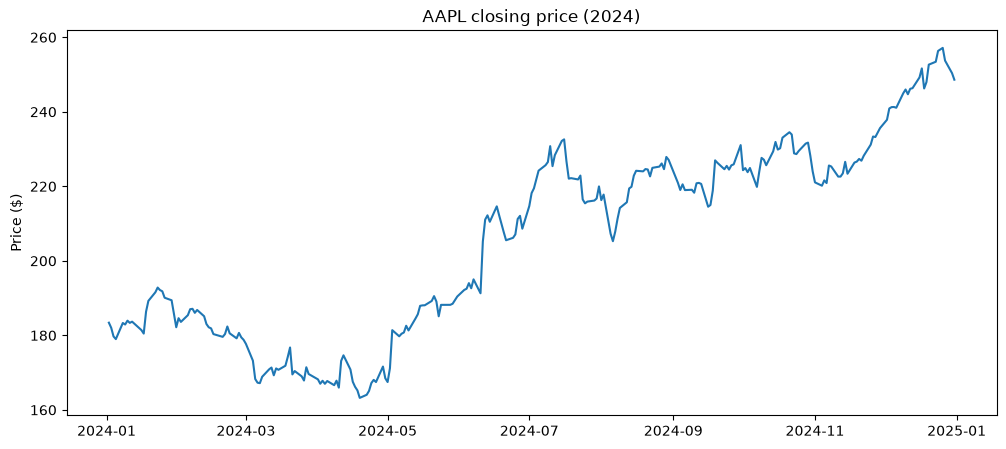

In [3]:
plt.figure(figsize=(12, 5))
plt.plot(data.index, data)
plt.title('AAPL closing price (2024)')
plt.ylabel('Price ($)')
plt.show()

In [4]:
# Option parameters
K = 250       # strike (close to the money)
T = 1.0       # one year to expiry
r = 0.04      # risk-free rate (assumed)

## 1. Black-Scholes closed form

$$C = S_0 N(d_1) - K e^{-rT} N(d_2), \qquad P = K e^{-rT} N(-d_2) - S_0 N(-d_1)$$

$$d_1 = \frac{\ln(S_0/K) + (r + \tfrac{1}{2}\sigma^2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

where $N$ is the standard normal CDF.

In [5]:
def d1_d2(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return d1, d2

def bs_call(S, K, T, r, sigma):
    d1, d2 = d1_d2(S, K, T, r, sigma)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

def bs_put(S, K, T, r, sigma):
    d1, d2 = d1_d2(S, K, T, r, sigma)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

In [6]:
call_bs = bs_call(S0, K, T, r, sigma)
put_bs = bs_put(S0, K, T, r, sigma)

print('Black-Scholes call:', round(call_bs, 4))
print('Black-Scholes put: ', round(put_bs, 4))

Black-Scholes call: 26.1877
Black-Scholes put:  17.7693


### Put-call parity

For European options on a non-dividend stock, holding a call and selling a put is the same as holding the stock and borrowing the discounted strike:

$$C - P = S_0 - K e^{-rT}$$

In [7]:
lhs = call_bs - put_bs
rhs = S0 - K * np.exp(-r * T)
print('C - P:          ', lhs)
print('S0 - K*exp(-rT):', rhs)
print('Difference:     ', abs(lhs - rhs))

# Check it across a range of strikes too
strikes = np.linspace(150, 350, 41)
parity_error = (bs_call(S0, strikes, T, r, sigma) - bs_put(S0, strikes, T, r, sigma)) - (S0 - strikes * np.exp(-r * T))
print('Max parity error over 41 strikes:', np.max(np.abs(parity_error)))

C - P:           8.418423903325419
S0 - K*exp(-rT): 8.418423903325447
Difference:      2.842170943040401e-14
Max parity error over 41 strikes: 5.684341886080802e-14


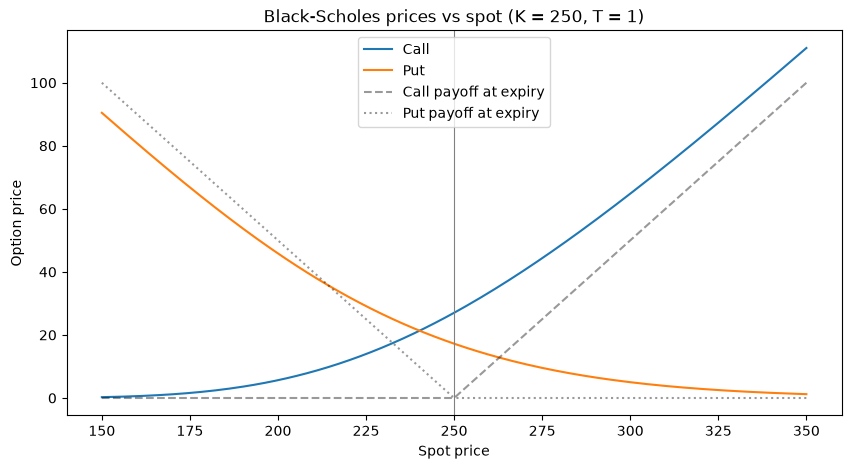

In [8]:
spots = np.linspace(150, 350, 200)

plt.figure(figsize=(10, 5))
plt.plot(spots, bs_call(spots, K, T, r, sigma), label='Call')
plt.plot(spots, bs_put(spots, K, T, r, sigma), label='Put')
plt.plot(spots, np.maximum(spots - K, 0), 'k--', alpha=0.4, label='Call payoff at expiry')
plt.plot(spots, np.maximum(K - spots, 0), 'k:', alpha=0.4, label='Put payoff at expiry')
plt.axvline(K, color='grey', linewidth=0.8)
plt.title('Black-Scholes prices vs spot (K = 250, T = 1)')
plt.xlabel('Spot price')
plt.ylabel('Option price')
plt.legend()
plt.show()

## 2. Simulating geometric Brownian motion

To simulate whole paths I split $[0, T]$ into $n$ steps of size $\Delta t = T/n$ and use the exact update

$$S_{t+\Delta t} = S_t \exp\left(\left(r - \tfrac{1}{2}\sigma^2\right)\Delta t + \sigma\sqrt{\Delta t}\,Z\right)$$

In [9]:
def simulate_gbm(S0, r, sigma, T, n_steps, n_paths):
    dt = T / n_steps
    Z = np.random.standard_normal((n_paths, n_steps))
    increments = (r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
    log_paths = np.cumsum(increments, axis=1)
    log_paths = np.hstack([np.zeros((n_paths, 1)), log_paths])  # start every path at S0
    return S0 * np.exp(log_paths)

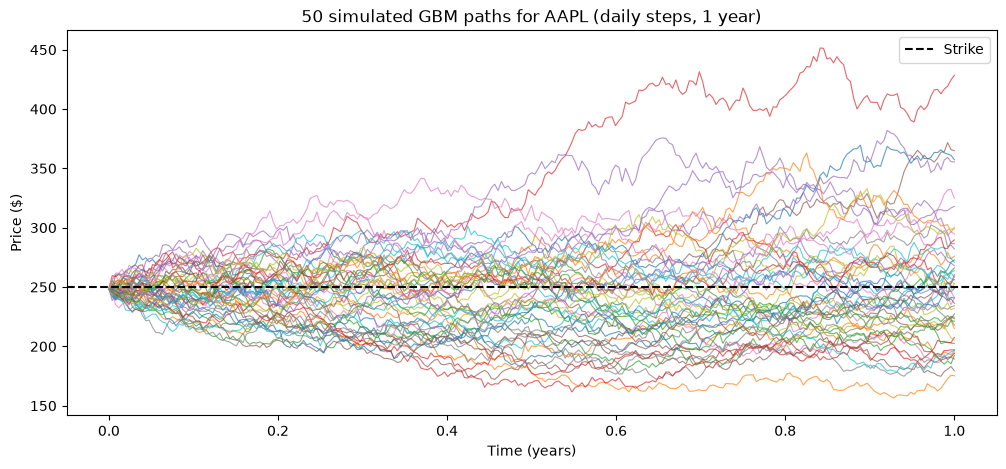

In [10]:
paths = simulate_gbm(S0, r, sigma, T, 252, 50)
t = np.linspace(0, T, 253)

plt.figure(figsize=(12, 5))
plt.plot(t, paths.T, linewidth=0.8, alpha=0.7)
plt.axhline(K, color='black', linestyle='--', label='Strike')
plt.title('50 simulated GBM paths for AAPL (daily steps, 1 year)')
plt.xlabel('Time (years)')
plt.ylabel('Price ($)')
plt.legend()
plt.show()

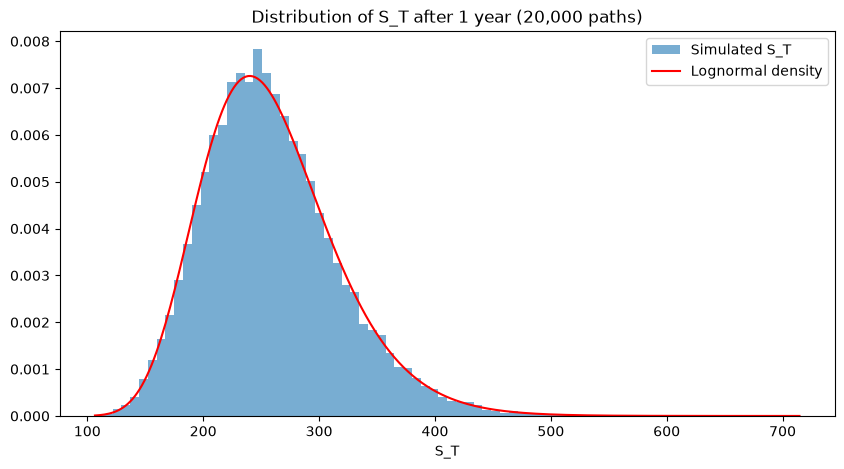

Mean of simulated S_T: 258.5
Theoretical mean S0*exp(rT): 258.76


In [11]:
# Check the terminal distribution against the lognormal density
paths = simulate_gbm(S0, r, sigma, T, 252, 20000)
ST = paths[:, -1]

x = np.linspace(ST.min(), ST.max(), 300)
mu_log = np.log(S0) + (r - 0.5 * sigma**2) * T
pdf = norm.pdf(np.log(x), mu_log, sigma * np.sqrt(T)) / x

plt.figure(figsize=(10, 5))
plt.hist(ST, bins=80, density=True, alpha=0.6, label='Simulated S_T')
plt.plot(x, pdf, 'r', label='Lognormal density')
plt.title('Distribution of S_T after 1 year (20,000 paths)')
plt.xlabel('S_T')
plt.legend()
plt.show()

print('Mean of simulated S_T:', round(ST.mean(), 2))
print('Theoretical mean S0*exp(rT):', round(S0 * np.exp(r * T), 2))